Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8943 - loss: 0.3780 - val_accuracy: 0.9432 - val_loss: 0.2016
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9493 - loss: 0.1753 - val_accuracy: 0.9583 - val_loss: 0.1460
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9637 - loss: 0.1262 - val_accuracy: 0.9673 - val_loss: 0.1176
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9724 - loss: 0.0980 - val_accuracy: 0.9715 - val_loss: 0.0984
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9772 - loss: 0.0796 - val_accuracy: 0.9747 - val_loss: 0.0905
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8925 - loss: 0.5157 - val_accuracy: 0.9367 - val_loss: 0.3266
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9426 - loss: 0.2966 - val_accuracy: 0.9505 - val_loss: 0.2594
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9531 - loss: 0.2431 - val_accuracy: 0.

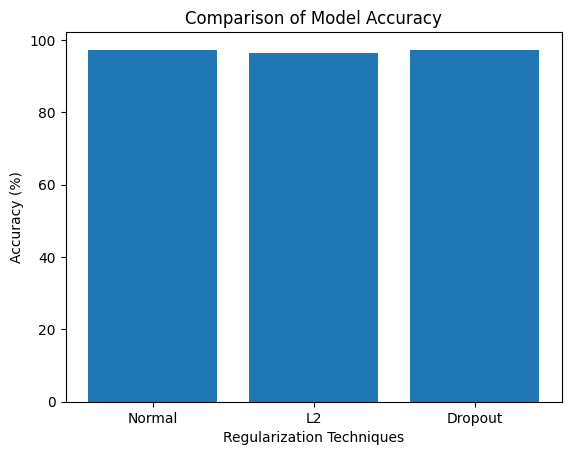

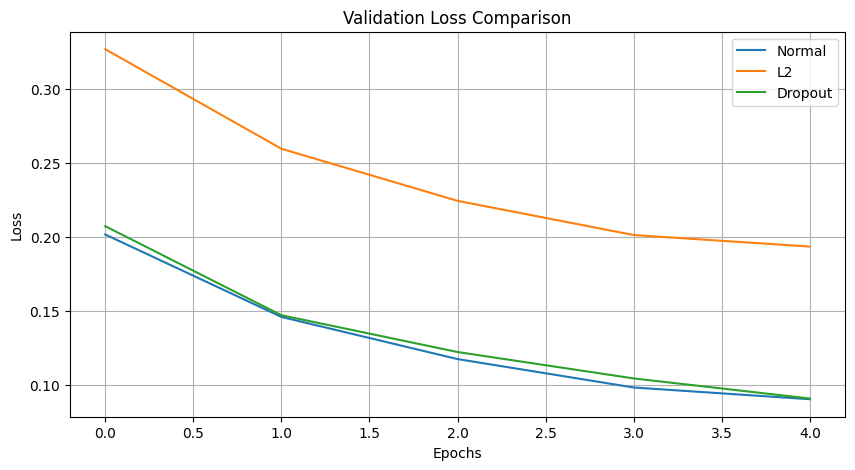

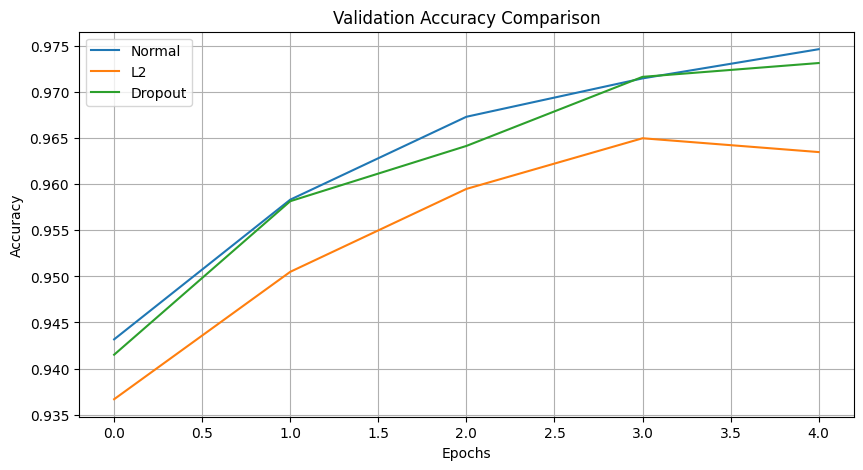

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from sklearn.model_selection import train_test_split

# Load MNIST dataset
data = np.load('mnist.npz')

x_train = data['x_train']
y_train = data['y_train']
x_test = data['x_test']
y_test = data['y_test']

# Flatten and normalize
x_train = x_train.reshape(-1, 784) / 255.0
x_test = x_test.reshape(-1, 784) / 255.0

# Split training and validation data
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.1, random_state=42
)

# Normal model
model1 = Sequential([
    tf.keras.Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model1.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

history1 = model1.fit(x_train, y_train, epochs=5, batch_size=128,
                      validation_data=(x_val, y_val))

# L2 Regularization model
model2 = Sequential([
    tf.keras.Input(shape=(784,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(10, activation='softmax')
])

model2.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

history2 = model2.fit(x_train, y_train, epochs=5, batch_size=128,
                      validation_data=(x_val, y_val))

# Dropout model
model3 = Sequential([
    tf.keras.Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

model3.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

history3 = model3.fit(x_train, y_train, epochs=5, batch_size=128,
                      validation_data=(x_val, y_val))

# Evaluate models
acc1 = model1.evaluate(x_test, y_test, verbose=0)[1]
acc2 = model2.evaluate(x_test, y_test, verbose=0)[1]
acc3 = model3.evaluate(x_test, y_test, verbose=0)[1]

print("Normal Model Accuracy:", acc1 * 100, "%")
print("L2 Model Accuracy:", acc2 * 100, "%")
print("Dropout Model Accuracy:", acc3 * 100, "%")

# Accuracy comparison
plt.bar(['Normal', 'L2', 'Dropout'],
        [acc1*100, acc2*100, acc3*100])
plt.title("Comparison of Model Accuracy")
plt.xlabel("Regularization Techniques")
plt.ylabel("Accuracy (%)")
plt.show()

# Validation loss comparison
plt.figure(figsize=(10, 5))
plt.plot(history1.history['val_loss'], label='Normal')
plt.plot(history2.history['val_loss'], label='L2')
plt.plot(history3.history['val_loss'], label='Dropout')
plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()

# Validation accuracy comparison
plt.figure(figsize=(10, 5))
plt.plot(history1.history['val_accuracy'], label='Normal')
plt.plot(history2.history['val_accuracy'], label='L2')
plt.plot(history3.history['val_accuracy'], label='Dropout')
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()
plt.show()

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)
Training: (54000, 784)
Validation: (6000, 784)
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8939 - loss: 0.3798 - val_accuracy: 0.9375 - val_loss: 0.2161
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9483 - loss: 0.1811 - val_accuracy: 0.9553 - val_loss: 0.1558
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9623 - loss: 0.1307 - val_accuracy: 0.9653 - val_loss: 0.1256
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9719 - loss: 0.1000 - val_accuracy: 0.9698 - val_loss: 0.1038
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9774 - loss: 0.0802 - val_accuracy: 0.9707 - val_loss: 0.0974
Normal model training completed!
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8990 - loss: 0.4996 - val_accuracy: 0.9398 - val_loss: 0.3185
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9481 - loss: 0.2787 - val_accura

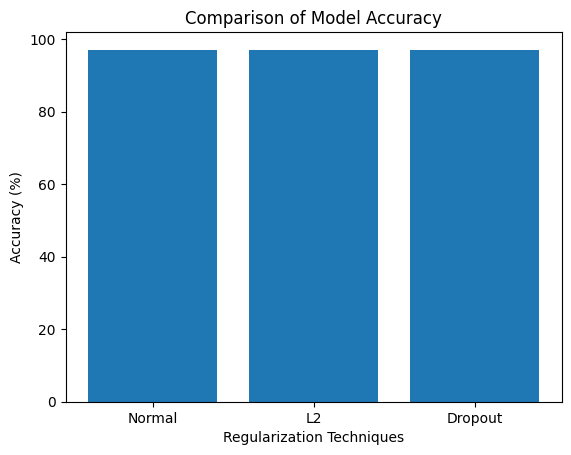

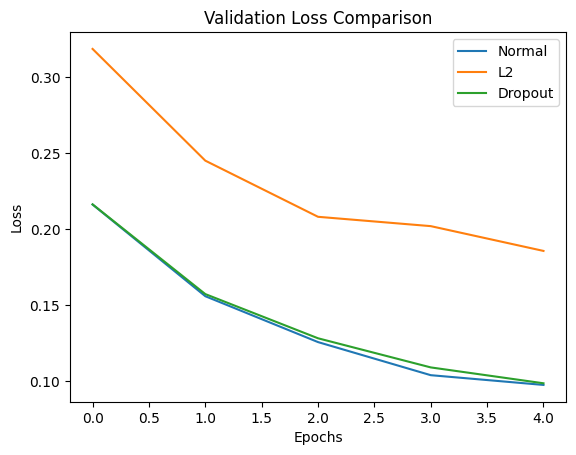

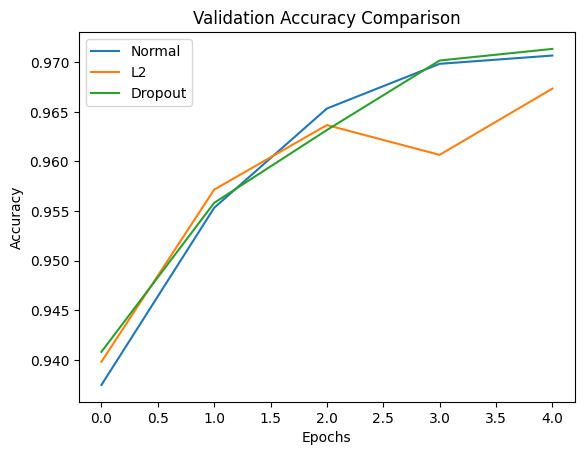

In [4]:
# Step 1: Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from sklearn.model_selection import train_test_split

# Step 2: Load Dataset
data = np.load('mnist.npz')
x_train, y_train = data['x_train'], data['y_train']
x_test, y_test = data['x_test'], data['y_test']

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)
'''
# Step 2: Load Local MNIST Dataset
data = np.load('mnist.npz')

x_train = data['x_train']
y_train = data['y_train']
x_test = data['x_test']
y_test = data['y_test']

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

(x_train, y_train), (x_test, y_test) = (
    (np.fromfile('MNIST/train-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/train-labels-idx1-ubyte', np.uint8)[8:]),
    (np.fromfile('MNIST/t10k-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/t10k-labels-idx1-ubyte', np.uint8)[8:])
)

'''
# Step 3: Preprocess Dataset
x_train = x_train.reshape(-1, 784) / 255.0
x_test = x_test.reshape(-1, 784) / 255.0

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.1, random_state=42
)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)

# Step 4: Define and Train Models
def train_model(regularization=None):

    layers = [
        tf.keras.Input(shape=(784,)),
        Dense(128, activation='relu',
              kernel_regularizer=regularization if regularization != 'dropout' else None)
    ]

    if regularization == 'dropout':
        layers.append(Dropout(0.3))

    layers.append(Dense(10, activation='softmax'))

    model = Sequential(layers)

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    history = model.fit(
        x_train, y_train, epochs=5, batch_size=128,
        validation_data=(x_val, y_val)
    )

    return model, history
# Step 5: Train Normal, L2 and Dropout Models
model1, history1 = train_model()
print("Normal model training completed!")

model2, history2 = train_model(l2(0.001))
print("L2 model training completed!")

model3, history3 = train_model('dropout')
print("Dropout model training completed!")

# Step 6: Evaluate Models
models = [model1, model2, model3]
histories = [history1, history2, history3]
names = ['Normal', 'L2', 'Dropout']

accuracies = [
    model.evaluate(x_test, y_test, verbose=0)[1] * 100
    for model in models
]

for name, acc in zip(names, accuracies):
    print(name, "Model Accuracy:", acc, "%")

# Step 7: Accuracy Comparison
plt.bar(names, accuracies)
plt.title("Comparison of Model Accuracy")
plt.xlabel("Regularization Techniques")
plt.ylabel("Accuracy (%)")
plt.show()

# Step 8: Validation Loss Comparison
for history, name in zip(histories, names):
    plt.plot(history.history['val_loss'], label=name)

plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Step 9: Validation Accuracy Comparison
for history, name in zip(histories, names):
    plt.plot(history.history['val_accuracy'], label=name)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8949 - loss: 0.3798 - val_accuracy: 0.9442 - val_loss: 0.2110
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9492 - loss: 0.1780 - val_accuracy: 0.9577 - val_loss: 0.1468
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9630 - loss: 0.1294 - val_accuracy: 0.9660 - val_loss: 0.1186
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9714 - loss: 0.1007 - val_accuracy: 0.9685 - val_loss: 0.1026
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9758 - loss: 0.0829 - val_accuracy: 0.9702 - val_loss: 0.0939
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8944 - loss: 0.5108 - val_accuracy: 0.9358 - val_loss: 0.3247
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9446 - loss: 0.2890 - val_accuracy: 0.9540 - val_loss: 0.2542
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9559 - loss: 0.2347 - val_accuracy: 0.958

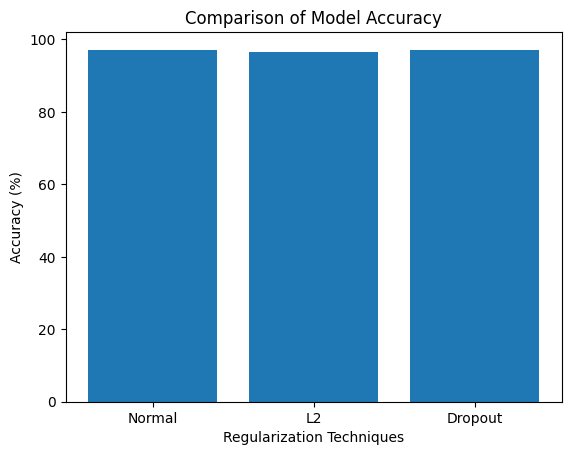

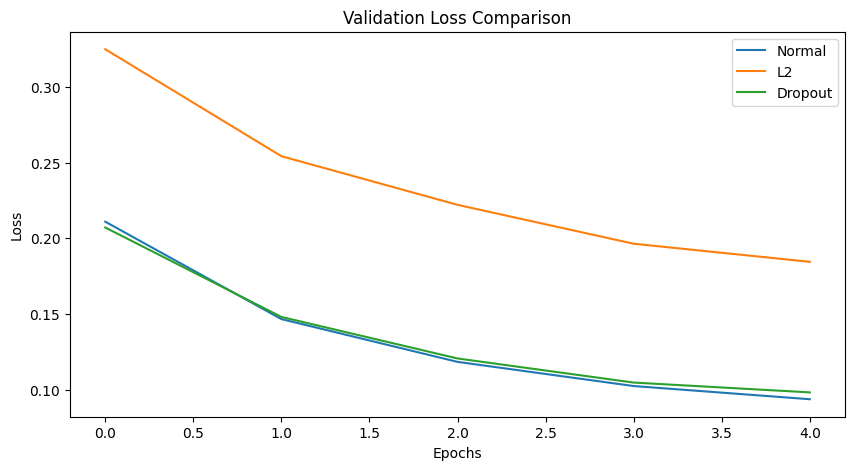

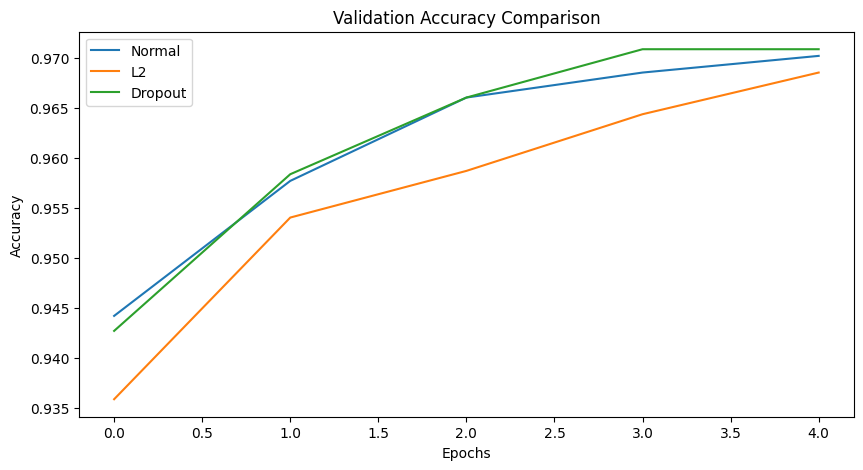

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import struct

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from sklearn.model_selection import train_test_split

# Load images
def load_images(file):
    with open(file, 'rb') as f:
        magic, num, rows, cols = struct.unpack('>IIII', f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
    return images.reshape(num, rows, cols)

# Load labels
def load_labels(file):
    with open(file, 'rb') as f:
        magic, num = struct.unpack('>II', f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

# Load MNIST dataset
x_train = load_images('MNIST/train-images-idx3-ubyte')
y_train = load_labels('MNIST/train-labels-idx1-ubyte')
x_test = load_images('MNIST/t10k-images-idx3-ubyte')
y_test = load_labels('MNIST/t10k-labels-idx1-ubyte')

# Flatten and normalize
x_train = x_train.reshape(-1, 784) / 255.0
x_test = x_test.reshape(-1, 784) / 255.0

# Split training and validation data
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.1, random_state=42
)

# Normal model
model1 = Sequential([
    tf.keras.Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model1.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

history1 = model1.fit(x_train, y_train, epochs=5, batch_size=128,
                      validation_data=(x_val, y_val))

# L2 Regularization model
model2 = Sequential([
    tf.keras.Input(shape=(784,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(10, activation='softmax')
])

model2.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

history2 = model2.fit(x_train, y_train, epochs=5, batch_size=128,
                      validation_data=(x_val, y_val))

# Dropout model
model3 = Sequential([
    tf.keras.Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

model3.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

history3 = model3.fit(x_train, y_train, epochs=5, batch_size=128,
                      validation_data=(x_val, y_val))

# Evaluate models
acc1 = model1.evaluate(x_test, y_test, verbose=0)[1]
acc2 = model2.evaluate(x_test, y_test, verbose=0)[1]
acc3 = model3.evaluate(x_test, y_test, verbose=0)[1]

print("Normal Model Accuracy:", acc1 * 100, "%")
print("L2 Model Accuracy:", acc2 * 100, "%")
print("Dropout Model Accuracy:", acc3 * 100, "%")

# Accuracy comparison
plt.bar(['Normal', 'L2', 'Dropout'],
        [acc1*100, acc2*100, acc3*100])
plt.title("Comparison of Model Accuracy")
plt.xlabel("Regularization Techniques")
plt.ylabel("Accuracy (%)")
plt.show()

# Validation loss comparison
plt.figure(figsize=(10, 5))
plt.plot(history1.history['val_loss'], label='Normal')
plt.plot(history2.history['val_loss'], label='L2')
plt.plot(history3.history['val_loss'], label='Dropout')
plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Validation accuracy comparison
plt.figure(figsize=(10, 5))
plt.plot(history1.history['val_accuracy'], label='Normal')
plt.plot(history2.history['val_accuracy'], label='L2')
plt.plot(history3.history['val_accuracy'], label='Dropout')
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

C:\Users\dgaid\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9208 - loss: 0.2709 - val_accuracy: 0.9590 - val_loss: 0.1384
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9659 - loss: 0.1133 - val_accuracy: 0.9678 - val_loss: 0.1105
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9759 - loss: 0.0768 - val_accuracy: 0.9690 - val_loss: 0.1009
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9819 - loss: 0.0561 - val_accuracy: 0.9762 - val_loss: 0.0899
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9851 - loss: 0.0464 - val_accuracy: 0.9739 - val_loss: 0.0922
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9191 - loss: 0.4586 - val_accuracy: 0.9553 - val_loss: 0.3029
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9572 - loss: 0.2807 - val_accuracy: 0.9618 - val_loss: 0.2550
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9639 - loss: 0.2383 - v

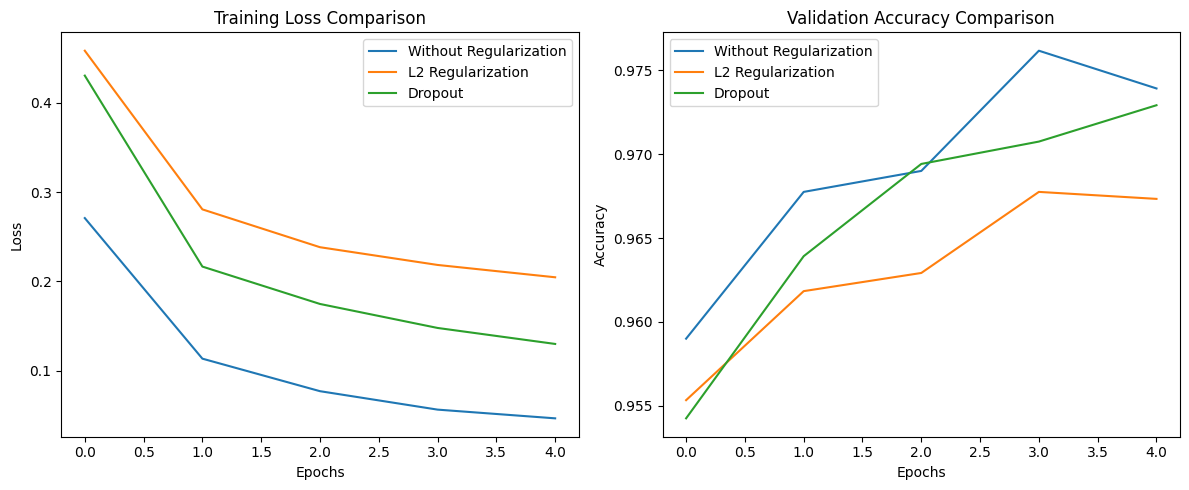

In [1]:
# Step 1: Import Libraries
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

# Step 2: Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Step 3: Normalize the Data
x_train = x_train / 255.0
x_test = x_test / 255.0

# Step 4: Create Model Without Regularization
model1 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 5: Train Model Without Regularization
history1 = model1.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

# Step 6: Create Model With L2 Regularization
model2 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(10, activation='softmax')
])

model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 7: Train Model With L2 Regularization
history2 = model2.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

# Step 8: Create Model With Dropout
model3 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

model3.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 9: Train Model With Dropout
history3 = model3.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

# Step 10: Compare Model Performance
print("\nModel Performance Comparison")

print("Without Regularization:",
      model1.evaluate(x_test, y_test, verbose=0))

print("With L2 Regularization:",
      model2.evaluate(x_test, y_test, verbose=0))

print("With Dropout:",
      model3.evaluate(x_test, y_test, verbose=0))

# Step 11: Visualize Training and Validation Loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history1.history['loss'], label='Without Regularization')
plt.plot(history2.history['loss'], label='L2 Regularization')
plt.plot(history3.history['loss'], label='Dropout')
plt.title('Training Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Step 12: Visualize Training and Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(history1.history['val_accuracy'], label='Without Regularization')
plt.plot(history2.history['val_accuracy'], label='L2 Regularization')
plt.plot(history3.history['val_accuracy'], label='Dropout')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

Training Baseline...
Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.9000 - loss: 0.3627 - val_accuracy: 0.9368 - val_loss: 0.2134
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.9457 - loss: 0.1904 - val_accuracy: 0.9540 - val_loss: 0.1543
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9589 - loss: 0.1432 - val_accuracy: 0.9633 - val_loss: 0.1242
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9682 - loss: 0.1143 - val_accuracy: 0.9690 - val_loss: 0.1079
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9736 - loss: 0.0954 - val_accuracy: 0.9724 - val_loss: 0.0961
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9772 - loss: 0.0814 - val_accuracy: 0.9739 - val_loss: 0.0880
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.9798 - loss: 0.0710 - val_accuracy: 0.9765 - val_loss: 0.0804
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9826

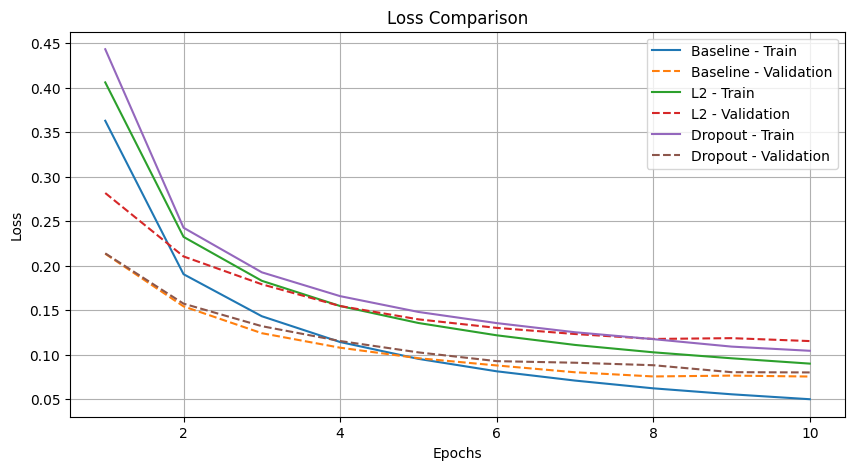

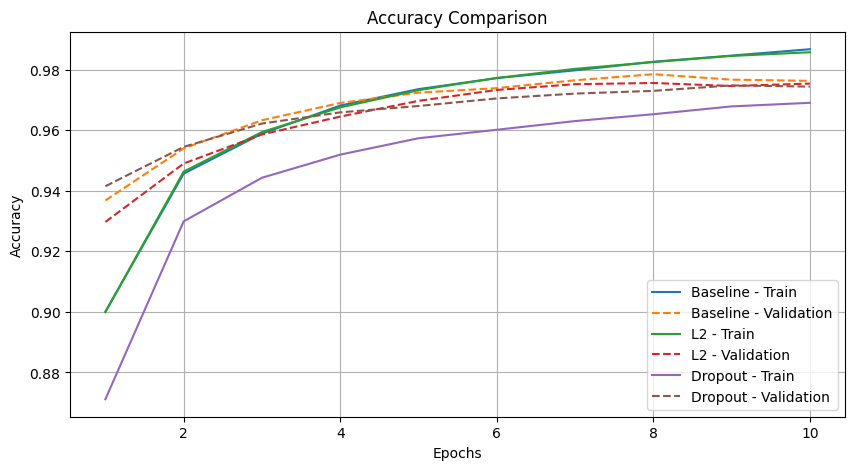

In [2]:
# 1. Import Libraries
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
import matplotlib.pyplot as plt

# 2. Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0


# 3. Define Model Architecture
def create_model(l2_reg=False, dropout=False):

    model = models.Sequential([
        layers.Flatten(input_shape=(28, 28)),

        layers.Dense(
            256,
            activation='relu',
            kernel_regularizer=regularizers.l2(0.0001) if l2_reg else None
        ),

        layers.Dropout(0.5) if dropout else layers.Activation('linear'),

        layers.Dense(10, activation='softmax')
    ])

    return model


# 4. Training and Evaluation Function
def train_and_evaluate(model, epochs=10):

    model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        x_train, y_train,
        epochs=epochs,
        batch_size=64,
        validation_data=(x_test, y_test),
        verbose=1
    )

    return (
        history.history['loss'],
        history.history['val_loss'],
        history.history['accuracy'],
        history.history['val_accuracy']
    )


# 5. Train Models
results = {}

# a. Baseline (Without Regularization)
model = create_model()

print("Training Baseline...")
results["Baseline"] = train_and_evaluate(model)


# b. L2 Regularization
model_l2 = create_model(l2_reg=True)

print("\nTraining with L2 Regularization...")
results["L2"] = train_and_evaluate(model_l2)


# c. Dropout Regularization
model_dropout = create_model(dropout=True)

print("\nTraining with Dropout...")
results["Dropout"] = train_and_evaluate(model_dropout)


# 6. Plotting
epochs = range(1, 11)


def plot_metric(metric_idx, title, ylabel):

    plt.figure(figsize=(10, 5))

    for label, (tl, vl, ta, va) in results.items():

        if metric_idx == 0:
            train_metric = tl
            val_metric = vl
        else:
            train_metric = ta
            val_metric = va

        plt.plot(epochs, train_metric, label=f"{label} - Train")
        plt.plot(epochs, val_metric, linestyle='--',
                 label=f"{label} - Validation")

    plt.title(title)
    plt.xlabel("Epochs")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True)
    plt.show()


# 7. Visualize Loss and Accuracy
plot_metric(0, "Loss Comparison", "Loss")
plot_metric(1, "Accuracy Comparison", "Accuracy")

Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)

Training Baseline...
Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.8919 - loss: 0.3925 - val_accuracy: 0.9342 - val_loss: 0.2341
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9412 - loss: 0.2095 - val_accuracy: 0.9542 - val_loss: 0.1711
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9561 - loss: 0.1574 - val_accuracy: 0.9610 - val_loss: 0.1409
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9648 - loss: 0.1260 - val_accuracy: 0.9654 - val_loss: 0.1255
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9704 - loss: 0.1048 - val_accuracy: 0.9694 - val_loss: 0.1123
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9757 - loss: 0.0894 - val_accuracy: 0.9688 - val_loss: 0.1071
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9787 - loss: 0.0777 - val_accuracy: 0.9714 - val_loss: 0.1027
Epoch 8/10
7

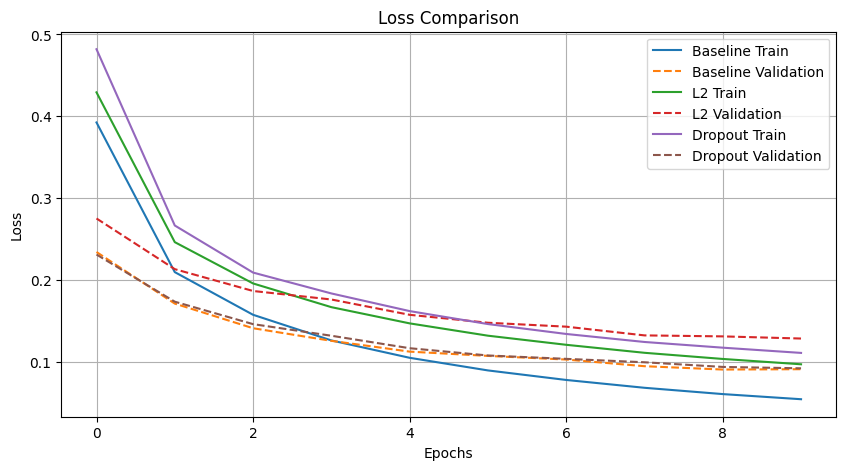

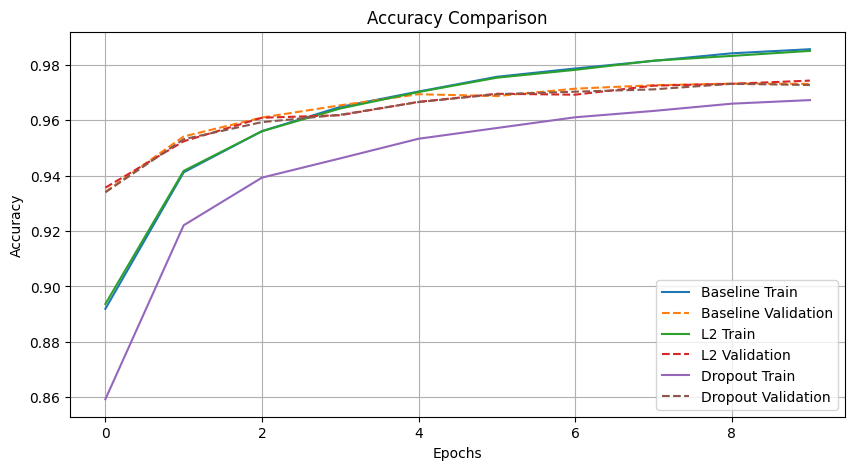

In [4]:
# 1. Import Libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import struct
import os

from tensorflow.keras import layers, models, regularizers

# 2. Load MNIST Dataset from Local Folder
path = "mnist"

def load_images(file):
    with open(os.path.join(path, file), 'rb') as f:
        magic, count, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        return images.reshape(count, rows, cols)

def load_labels(file):
    with open(os.path.join(path, file), 'rb') as f:
        magic, count = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

x_train = load_images("train-images-idx3-ubyte")
y_train = load_labels("train-labels-idx1-ubyte")
x_test = load_images("t10k-images-idx3-ubyte")
y_test = load_labels("t10k-labels-idx1-ubyte")

# 3. Normalize Data
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

# 4. Define Model Architecture
def create_model(l2_reg=False, dropout=False):

    model = models.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),

        layers.Dense(
            256,
            activation='relu',
            kernel_regularizer=regularizers.l2(0.0001) if l2_reg else None
        ),

        layers.Dropout(0.5) if dropout else layers.Activation('linear'),

        layers.Dense(10, activation='softmax')
    ])

    return model

# 5. Training and Evaluation Function
def train_and_evaluate(model, epochs=10):

    model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        x_train, y_train,
        epochs=epochs,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )

    return history

# 6. Train Models
results = {}

# Without Regularization
print("\nTraining Baseline...")
model = create_model()
results["Baseline"] = train_and_evaluate(model)

# With L2 Regularization
print("\nTraining with L2...")
model_l2 = create_model(l2_reg=True)
results["L2"] = train_and_evaluate(model_l2)

# With Dropout
print("\nTraining with Dropout...")
model_dropout = create_model(dropout=True)
results["Dropout"] = train_and_evaluate(model_dropout)

# 7. Plot Training and Validation Loss
plt.figure(figsize=(10, 5))

for name, history in results.items():
    plt.plot(history.history['loss'], label=name + ' Train')
    plt.plot(history.history['val_loss'], '--', label=name + ' Validation')

plt.title("Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# 8. Plot Training and Validation Accuracy
plt.figure(figsize=(10, 5))

for name, history in results.items():
    plt.plot(history.history['accuracy'], label=name + ' Train')
    plt.plot(history.history['val_accuracy'], '--', label=name + ' Validation')

plt.title("Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9053 - loss: 0.3404 - val_accuracy: 0.9464 - val_loss: 0.1876
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9553 - loss: 0.1526 - val_accuracy: 0.9620 - val_loss: 0.1313
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9687 - loss: 0.1075 - val_accuracy: 0.9668 - val_loss: 0.1116
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9757 - loss: 0.0834 - val_accuracy: 0.9680 - val_loss: 0.1079
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9808 - loss: 0.0660 - val_accuracy: 0.9692 - val_loss: 0.1011
Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9078 - loss: 0.3509 - val_accuracy: 0.9470 - val_loss: 0.2088
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9548 - loss: 0.1804 - val_accuracy: 0.9587 - val_loss: 0.1678
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.9666 - loss: 0.1399 - val_accuracy: 

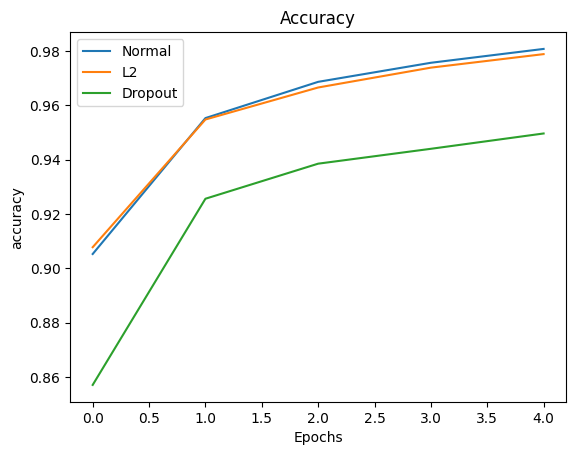

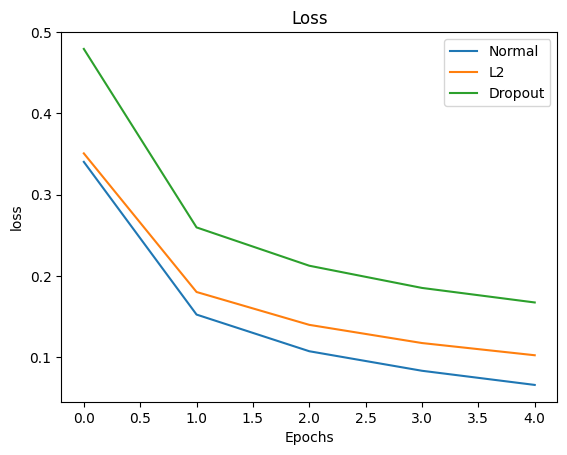

In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, regularizers

# Load MNIST dataset
data = np.load('mnist.npz')
x_train, y_train = data['x_train'], data['y_train']
x_test, y_test = data['x_test'], data['y_test']

# Normalize data
x_train, x_test = x_train / 255.0, x_test / 255.0

# Create model
def create_model(reg=None, drop=False):
    model = tf.keras.Sequential([
        layers.Flatten(input_shape=(28, 28)),
        layers.Dense(128, activation='relu', kernel_regularizer=reg),
        layers.Dropout(0.5) if drop else layers.Activation('linear'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Train models
models = {
    'Normal': create_model(),
    'L2': create_model(regularizers.l2(0.0001)),
    'Dropout': create_model(drop=True)
}

history = {}
for name, model in models.items():
    history[name] = model.fit(x_train, y_train, epochs=5, batch_size=64,
                              validation_split=0.2, verbose=1)

# Evaluate models
for name, model in models.items():
    print(name, model.evaluate(x_test, y_test, verbose=0))

# Plot accuracy and loss
for metric in ['accuracy', 'loss']:
    for name, h in history.items():
        plt.plot(h.history[metric], label=name)
    plt.title(metric.capitalize())
    plt.xlabel('Epochs')
    plt.ylabel(metric)
    plt.legend()
    plt.show()


Training Baseline...
Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.8915 - loss: 0.3936 - val_accuracy: 0.9342 - val_loss: 0.2339
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9405 - loss: 0.2098 - val_accuracy: 0.9481 - val_loss: 0.1879
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - accuracy: 0.9544 - loss: 0.1595 - val_accuracy: 0.9572 - val_loss: 0.1515
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9637 - loss: 0.1291 - val_accuracy: 0.9650 - val_loss: 0.1295
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 60ms/step - accuracy: 0.9688 - loss: 0.1082 - val_accuracy: 0.9643 - val_loss: 0.1237
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 4ms/step - accuracy: 0.9747 - loss: 0.0919 - val_accuracy: 0.9689 - val_loss: 0.1086
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9777 - loss: 0.0805 - val_accuracy: 0.9712 - val_loss: 0.1025
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9806 - 

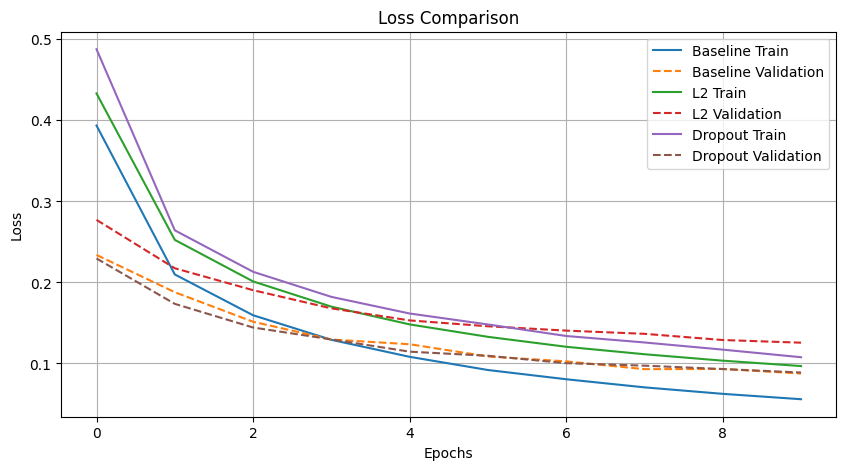

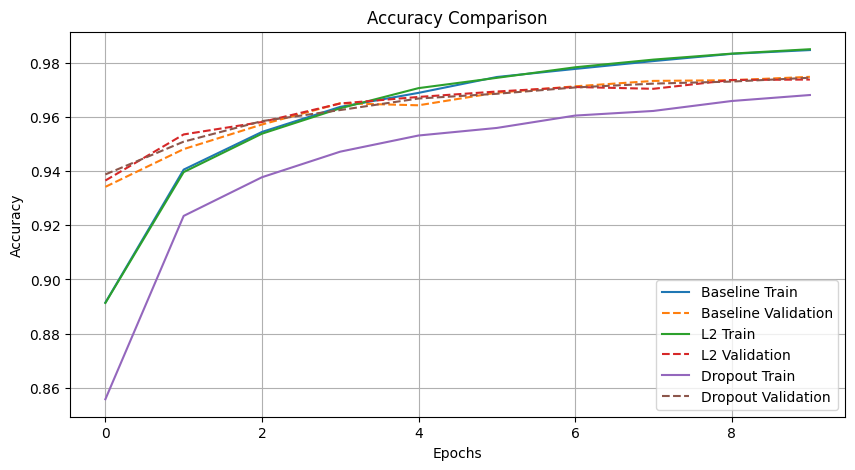

In [6]:
# 1. Import Libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, regularizers

# 2. Load MNIST Dataset
data = np.load('mnist.npz')

x_train = data['x_train']
y_train = data['y_train']
x_test = data['x_test']
y_test = data['y_test']

# 3. Normalize Data
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# 4. Define Model Architecture
def create_model(l2_reg=False, dropout=False):

    model = models.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),

        layers.Dense(
            256,
            activation='relu',
            kernel_regularizer=regularizers.l2(0.0001) if l2_reg else None
        ),

        layers.Dropout(0.5) if dropout else layers.Activation('linear'),

        layers.Dense(10, activation='softmax')
    ])

    return model

# 5. Training and Evaluation Function
def train_and_evaluate(model, epochs=10):

    model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        x_train, y_train,
        epochs=epochs,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )

    return history

# 6. Train Models
results = {}

print("\nTraining Baseline...")
model = create_model()
results["Baseline"] = train_and_evaluate(model)

print("\nTraining with L2...")
model_l2 = create_model(l2_reg=True)
results["L2"] = train_and_evaluate(model_l2)

print("\nTraining with Dropout...")
model_dropout = create_model(dropout=True)
results["Dropout"] = train_and_evaluate(model_dropout)

# 7. Plot Training and Validation Loss
plt.figure(figsize=(10, 5))

for name, history in results.items():
    plt.plot(history.history['loss'], label=name + ' Train')
    plt.plot(history.history['val_loss'], '--', label=name + ' Validation')

plt.title("Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# 8. Plot Training and Validation Accuracy
plt.figure(figsize=(10, 5))

for name, history in results.items():
    plt.plot(history.history['accuracy'], label=name + ' Train')
    plt.plot(history.history['val_accuracy'], '--', label=name + ' Validation')

plt.title("Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()